# 05 · Decision letters with Claude

A declined applicant deserves a clear explanation. Here Claude turns the model's decision, its reasons (notebook 04)
and the path to approval into a plain-language letter, and **every letter is checked before it could be sent**.

**How it stays faithful**

1. Claude never sees the applicant's data, only the *facts* the model produced, each with an ID
   (`R1…` reasons, `S1…` strengths, `P1…` steps).
2. Claude returns a **structured** letter (structured outputs): each reason and step sentence must cite one of those IDs.
   We assemble the final text and add our own footer offering a human review.
3. **Deterministic checks:** every main reason covered in order, no protected attributes, no promise of approval,
   no technical terms or feature codes, length limit.
4. **Faithfulness judge:** a second Claude call sees only the facts and the finished letter, and lists anything unsupported.
5. If anything fails, Claude gets the failures as feedback and tries once more.

Applicants whose main reasons include **family status or number of children** are sent to a human reviewer instead:
a letter must not cite them, and hiding a real reason would be dishonest.

Model: `claude-haiku-5-5` (Claude Haiku 5.5, medium effort), fast and low-cost, for every request. Haiku 5.5 has no server-side refusal fallback, so if it declines a request, the same request goes to `claude-opus-5-5`, which keeps its own server-side fallback; only if that chain declines too does a person write the letter. The cost of every run is tracked per model.

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().resolve().parent / "src"))  # import secondlook from src/ (no pip install needed)

import json
import os
from collections import Counter

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from dotenv import load_dotenv

from secondlook.config import FIGURES_DIR, MODELS_DIR, PROCESSED_DIR, ROOT
from secondlook.explain import path_to_approval, score, shap_values, top_reasons
from secondlook.features import load_features
from secondlook.letters import MODEL, LetterFacts, Usage, build_facts, generate, judge_letter
from secondlook.modeling import load_bundle, prepare

sns.set_theme(style="whitegrid", context="notebook")
BLUE, ORANGE, GREY, RED = "#4C72B0", "#DD8452", "#8C8C8C", "#C44E52"

def savefig(name):
    plt.tight_layout()
    plt.savefig(FIGURES_DIR / f"{name}.png", dpi=150, bbox_inches="tight")

load_dotenv(ROOT / ".env")
HAS_KEY = bool(os.environ.get("ANTHROPIC_API_KEY"))
print("Anthropic API key found:", HAS_KEY)

Anthropic API key found: True


## 1. Pick borderline declines and build their facts

In [2]:
bundle = load_bundle("secondlook_lgbm")
CUTOFF = json.loads((MODELS_DIR / "secondlook_lgbm_meta.json").read_text())["risk_appetite"]["cutoff"]

df = prepare(load_features())
test = df[df["split"] == "test"].copy()
test["PD"] = score(bundle, test)
borderline = test[(test["PD"] > CUTOFF) & (test["PD"] <= CUTOFF + 0.05)]

N_PER_GROUP = 10  # 10 thin-file + 10 with bureau history keeps the demo fast and cheap
sample = pd.concat([borderline[borderline["THIN_FILE"] == g].sample(N_PER_GROUP, random_state=1) for g in [1, 0]])
contrib, _ = shap_values(bundle, sample)

facts = []
for idx in sample.index:
    x = sample.loc[[idx]]
    reasons = top_reasons(contrib.loc[idx], x.iloc[0], n=3, direction="risk")
    strengths = top_reasons(contrib.loc[idx], x.iloc[0], n=3, direction="strength")
    options = path_to_approval(bundle, x, CUTOFF, max_options=2)
    facts.append(build_facts(x["SK_ID_CURR"].iloc[0], "declined", reasons, strengths, options))

print(f"{len(facts)} applicants; {sum(bool(f.steps) for f in facts)} have a path to approval; "
      f"{sum(bool(f.sensitive_reasons) for f in facts)} routed to a human reviewer (protected-related reason)")

20 applicants; 16 have a path to approval; 0 routed to a human reviewer (protected-related reason)


This is everything Claude is allowed to use for one applicant:

In [3]:
example = next(f for f in facts if f.steps)
print(example.as_prompt())

Decision: the application was declined.
Factors that RAISED the assessed risk (most important first):
  R1: average external credit score
  R2: loan size relative to the yearly repayment (loan term)
  R3: yearly repayment amount
Factors that LOWERED the assessed risk:
  S1: occupation
  S2: length of point-of-sale loan history
Changes that our model estimates would lead to approval if the applicant re-applied:
  P1: Choose a 40% cheaper purchase, so the loan and repayments are 40% smaller and pay 40% of the loan upfront as a bigger down payment


## 2. Generate and check the letters
Each letter takes two Claude calls (write + judge), or four if it needs a retry. A spending cap stops the run early if it is exceeded.

In [4]:
MAX_COST_USD = 3.00
usage = Usage()
results = []

if not HAS_KEY:
    print("Skipped: add ANTHROPIC_API_KEY to .env (see .env.example) and re-run this notebook.")
else:
    import anthropic
    client = anthropic.Anthropic()
    for f in facts:
        if usage.cost_usd > MAX_COST_USD:
            print(f"Stopped early: spending cap of ${MAX_COST_USD:.2f} reached.")
            break
        out = generate(client, f, usage)
        out["thin_file"] = int(sample.loc[sample["SK_ID_CURR"] == f.applicant_id, "THIN_FILE"].iloc[0])
        results.append(out)
    print(f"{len(results)} letters | {usage.calls} Claude calls | {usage.input_tokens:,} input + "
          f"{usage.output_tokens:,} output tokens | about ${usage.cost_usd:.2f} "
          f"(${usage.cost_usd / max(len(results), 1):.3f} per letter) | Haiku refusals escalated to Opus: {usage.escalations}")

20 letters | 40 Claude calls | 51,078 input + 19,178 output tokens | about $0.01 ($0.001 per letter) | Haiku refusals escalated to Opus: 0


In [5]:
if results:
    shown = next(r for r in results if r["passed"])
    print(shown["text"])

Subject: Your SecondLook loan application

Dear applicant,

We have reviewed your application and we are sorry to let you know that it has been declined.

Your average external credit score counted against your application because it raised the risk we assessed.
The size of the loan compared with the yearly repayment, which is linked to the loan term, counted against your application.
The yearly repayment amount counted against your application because it raised the risk we assessed.

Your occupation counted in your favour and lowered the risk we assessed.
The length of your point-of-sale loan history also counted in your favour and lowered the risk we assessed.

What could change the decision:
- One option is to choose a purchase that costs 40% less, so the loan and repayments would be 40% smaller, and to pay 40% of the loan upfront as a bigger down payment; our checks estimate this would lead to approval, but approval cannot be guaranteed.

Thank you for choosing SecondLook, and plea

## 3. How faithful are the letters?

outcome,Passed first time
thin_file,
0,10
1,10


Median length: 154 words


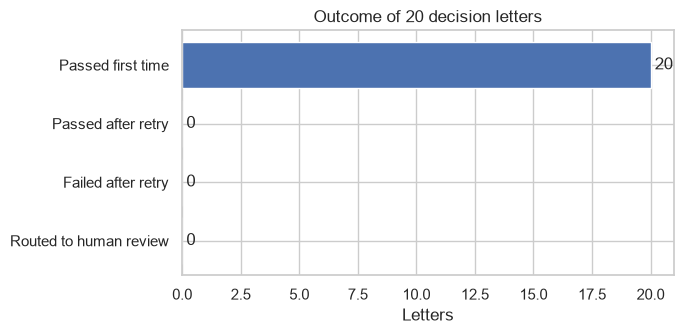

In [6]:
if results:
    res = pd.DataFrame([{
        "applicant_id": r["applicant_id"], "thin_file": r["thin_file"],
        "outcome": ("Routed to human review" if r["routed_to_review"] else
                    "Passed first time" if r["passed"] and r["attempts"] == 1 else
                    "Passed after retry" if r["passed"] else "Failed after retry"),
        "words": r["checks"]["words"] if r["checks"] else np.nan,
        "n_failures": len(r["failures"]),
    } for r in results])

    order = ["Passed first time", "Passed after retry", "Failed after retry", "Routed to human review"]
    counts = res["outcome"].value_counts().reindex(order, fill_value=0)
    fig, ax = plt.subplots(figsize=(7, 3.5))
    bars = ax.barh(counts.index[::-1], counts.values[::-1], color=[GREY, RED, ORANGE, BLUE])
    ax.bar_label(bars, padding=3)
    ax.set(title=f"Outcome of {len(res)} decision letters", xlabel="Letters")
    savefig("22_letter_outcomes")
    display(res.groupby("thin_file")["outcome"].value_counts().unstack(fill_value=0))
    print(f"Median length: {res['words'].median():.0f} words")

In [7]:
if results:
    # Failures on the FIRST attempt (before feedback) and on the final attempt, grouped by type.
    def kind(f):
        return f.split(":")[0].split("(")[0].strip()
    first = Counter(kind(f) for r in results if r.get("history") for f in r["history"][0])
    final = Counter(kind(f) for r in results if not r["passed"] for f in r["failures"])
    print("First-attempt failures:", dict(first) or "none")
    print("Failures remaining after the retry:", dict(final) or "none")
    for r in results:
        if r.get("history") and r["history"][0]:
            for f in r["history"][0][:2]:
                print(f"  first attempt, applicant {r['applicant_id']}: {f[:140]}")

First-attempt failures: none
Failures remaining after the retry: none


## 4. Does the judge actually catch problems?
A checker that never fails anything proves nothing. We take letters that passed, **insert a false statement**
that is not in the facts, and see whether the judge flags it.

In [8]:
PLANTED = [
    "We also noted a missed rent payment last year.",
    "Your employer's industry is considered high risk by our bank.",
    "Applicants from your area are often declined.",
    "Because you are still young, your credit history is short.",
    "If you reapply with a larger down payment you are guaranteed approval.",
]

if results:
    passed = [r for r in results if r["passed"]][: len(PLANTED)]
    caught = []
    for r, plant in zip(passed, PLANTED):
        f = next(f for f in facts if f.applicant_id == r["applicant_id"])
        tampered = r["text"].replace("What could change the decision:", plant + "\n\nWhat could change the decision:")
        if tampered == r["text"]:  # no steps section: append before the footer instead
            tampered = r["text"].replace("You can ask for a person", plant + "\n\nYou can ask for a person")
        v = judge_letter(client, f, tampered, usage)
        flagged = bool(v.unsupported_statements) or v.mentions_protected_attribute or v.promises_approval
        caught.append({"planted statement": plant, "caught": flagged,
                       "judge said": "; ".join(v.unsupported_statements)
                                     + (" [protected]" if v.mentions_protected_attribute else "")
                                     + (" [promise]" if v.promises_approval else "")})
    caught = pd.DataFrame(caught)
    print(f"Judge caught {caught['caught'].sum()} of {len(caught)} planted errors. Total spend so far: ${usage.cost_usd:.2f}")
    display(caught)

Judge caught 5 of 5 planted errors. Total spend so far: $0.02


,planted statement,caught,judge said
0,We also noted a missed rent payment last year.,True,We also noted a missed rent payment last year.
1,Your employer's industry is considered high ri...,True,Your employer's industry is considered high ri...
2,Applicants from your area are often declined.,True,Applicants from your area are often declined.
3,"Because you are still young, your credit histo...",True,"Because you are still young, your credit histo..."
4,If you reapply with a larger down payment you ...,True,If you reapply with a larger down payment you ...


## 5. Save the letters

In [9]:
if results:
    out_path = PROCESSED_DIR / "letters.jsonl"
    with out_path.open("w") as fh:
        for r in results:
            fh.write(json.dumps({"applicant_id": r["applicant_id"], "thin_file": r["thin_file"], "passed": r["passed"],
                                 "attempts": r["attempts"], "routed_to_review": r["routed_to_review"],
                                 "failures": r["failures"], "history": r.get("history"), "text": r["text"]}) + "\n")
    sample_md = ROOT / "docs" / "sample_letters.md"
    with_steps = [r for r in results if r["passed"] and "What could change" in r["text"]]
    without = [r for r in results if r["passed"] and "What could change" not in r["text"]]
    good = with_steps[:2] + without[:1]
    sample_md.write_text("# Sample decision letters\n\nGenerated by notebook 05 from the model's facts only, "
                         "and checked before sending.\n\n" + "\n\n---\n\n".join(f"```text\n{r['text']}\n```" for r in good))
    print("Saved", out_path.name, "and docs/sample_letters.md")

Saved letters.jsonl and docs/sample_letters.md


## Takeaways

Results for 20 borderline declines from the test split (10 thin-file, 10 with bureau history).

1. **Every letter passed every check on the first attempt** (20 of 20): all main reasons covered in order, no protected attributes, no promises, no technical terms, and nothing the faithfulness judge considered unsupported. Median length 154 words.
2. **The judge is not a rubber stamp.** We planted five false statements (an invented missed rent payment, an employer-industry claim, a postcode-style claim, an age reference, a guarantee of approval) into letters that had passed; the judge caught **5 of 5**.
3. **Getting here took two fixes, both found by the checks.** The first run had Claude explaining *why* factors matter (e.g. "which suggests past borrowing has not gone smoothly"), which is speculation the model never made; tightening the instructions removed it. The second run showed my own promise check flagging the disclaimer "this is not a guarantee"; the check now flags only real promises.
4. **Cheap enough to run on every decline.** On Claude Haiku 5.5 the run cost about $0.01–0.02 for 20 letters (about 0.1 cent each, write + judge) with no refusals, so Opus was never needed. The same run on Claude Opus 5.5 alone cost $0.41 with the same results (20 of 20 passed, 5 of 5 planted errors caught), so the smaller model is the right choice here. Haiku 5.5 has no server-side refusal fallback, so a declined request is retried on Opus 5.5, and goes to a human reviewer only if Opus declines too.
5. **Honest about limits.** Letters say what would change *the model's* decision, not what would make the applicant repay. Family status and number of children are no longer model inputs (notebook 08), so they cannot appear as reasons; the rule that routes such cases to a human stays as a safety net.